Iteration 20: Iteration best = 305.29, Best ever = 305.29
Iteration 40: Iteration best = 305.29, Best ever = 305.29
Iteration 60: Iteration best = 305.29, Best ever = 305.29
Iteration 80: Iteration best = 305.29, Best ever = 305.29
Iteration 100: Iteration best = 305.29, Best ever = 305.29
Iteration 120: Iteration best = 305.29, Best ever = 305.29
Iteration 140: Iteration best = 305.29, Best ever = 305.29
Iteration 160: Iteration best = 305.29, Best ever = 305.29
Iteration 180: Iteration best = 305.29, Best ever = 305.29
Iteration 200: Iteration best = 305.29, Best ever = 305.29

Random tours
Best of 1000 random tours: 487.8
Average random tour: 707.02

ACO + 2-opt results
Best route: 9 -> 2 -> 7 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0 -> 12 -> 4 -> 1 -> 6 -> 10 -> 9
Best distance: 305.29


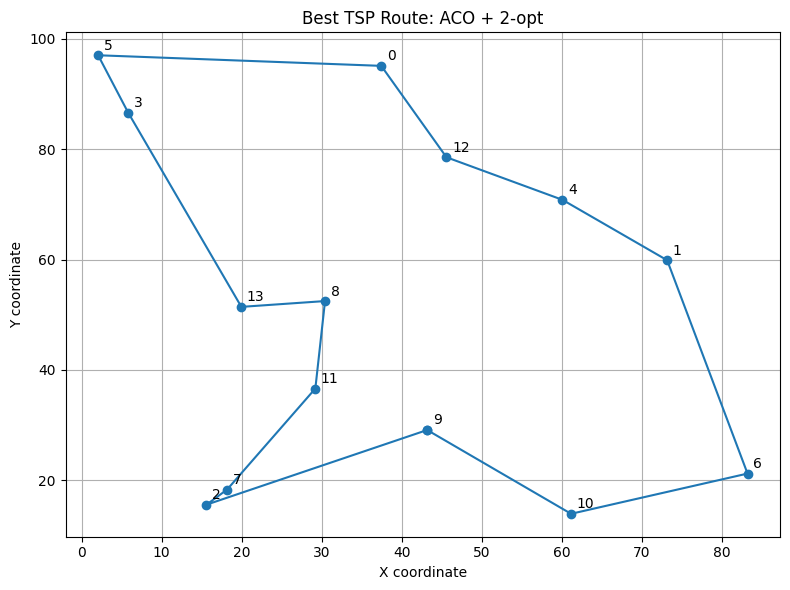

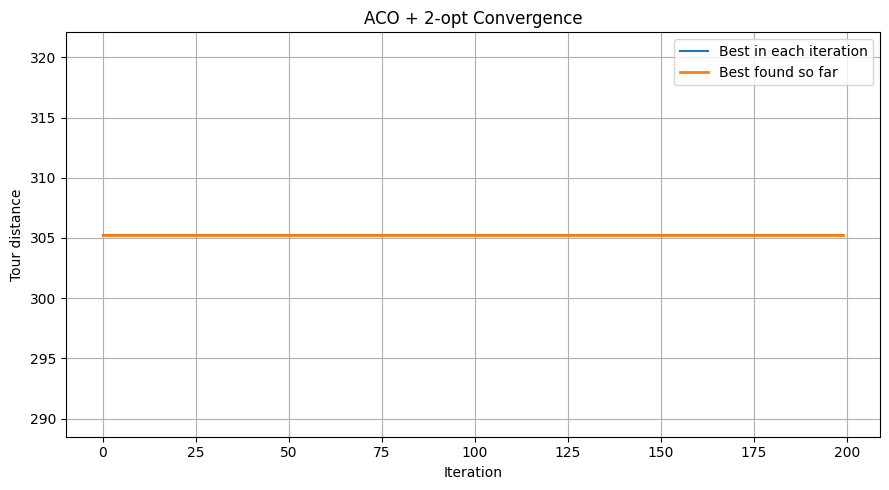

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Generate 14 cities
np.random.seed(42)
n_cities = 14
cities = np.random.rand(n_cities, 2) * 100

distance = np.linalg.norm(
    cities[:, None, :] - cities[None, :, :], axis=2
)
np.fill_diagonal(distance, 0)

# 2. Calculate the length of a closed tour
def tour_length(tour):
    return sum(
        distance[tour[i], tour[i + 1]]
        for i in range(len(tour) - 1)
    )

# 3. Improve a tour using 2-opt
def two_opt(tour):
    best = tour.copy()
    improved = True

    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                candidate = (
                    best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                )

                if tour_length(candidate) < tour_length(best) - 1e-9:
                    best = candidate
                    improved = True
                    break
            if improved:
                break

    return best

# 4. ACO parameters
n_ants = 30
n_iterations = 200
alpha = 1.0
beta = 3.0
rho = 0.3
Q = 100.0

rng = np.random.default_rng(42)
pheromone = np.ones((n_cities, n_cities))

best_tour = None
best_distance = float("inf")
best_history = []
iteration_history = []

# 5. ACO algorithm
for iteration in range(n_iterations):
    all_tours = []
    all_lengths = []

    for ant in range(n_ants):
        start = int(rng.integers(n_cities))
        tour = [start]
        unvisited = set(range(n_cities))
        unvisited.remove(start)

        while unvisited:
            current = tour[-1]
            choices = np.array(sorted(unvisited))

            tau = pheromone[current, choices] ** alpha
            eta = (1.0 / (distance[current, choices] + 1e-12)) ** beta

            weights = tau * eta
            probabilities = weights / weights.sum()

            next_city = int(rng.choice(choices, p=probabilities))
            tour.append(next_city)
            unvisited.remove(next_city)

        tour.append(start)

        # Apply local search to shorten this ant's route
        tour = two_opt(tour)
        length = tour_length(tour)

        all_tours.append(tour)
        all_lengths.append(length)

        if length < best_distance:
            best_distance = length
            best_tour = tour.copy()

    iteration_history.append(min(all_lengths))
    best_history.append(best_distance)

    # Evaporate pheromones
    pheromone *= (1 - rho)

    # Deposit pheromones from all ants
    for tour, length in zip(all_tours, all_lengths):
        deposit = Q / length
        for i in range(n_cities):
            a, b = tour[i], tour[i + 1]
            pheromone[a, b] += deposit
            pheromone[b, a] += deposit

    # Extra reinforcement for the best tour found so far
    for i in range(n_cities):
        a, b = best_tour[i], best_tour[i + 1]
        pheromone[a, b] += Q / best_distance
        pheromone[b, a] += Q / best_distance

    if (iteration + 1) % 20 == 0:
        print(
            f"Iteration {iteration + 1}: "
            f"Iteration best = {min(all_lengths):.2f}, "
            f"Best ever = {best_distance:.2f}"
        )

# 6. Compare against random tours
random_lengths = []
for _ in range(1000):
    route = list(rng.permutation(n_cities))
    route.append(route[0])
    random_lengths.append(tour_length(route))

print("\nRandom tours")
print("Best of 1000 random tours:", round(min(random_lengths), 2))
print("Average random tour:", round(np.mean(random_lengths), 2))

print("\nACO + 2-opt results")
print("Best route:", " -> ".join(map(str, best_tour)))
print("Best distance:", round(best_distance, 2))

# 7. Plot the best route
route_points = cities[best_tour]

plt.figure(figsize=(8, 6))
plt.plot(route_points[:, 0], route_points[:, 1], "o-")
for i, (x, y) in enumerate(cities):
    plt.annotate(str(i), (x, y), xytext=(4, 4),
                 textcoords="offset points")
plt.title("Best TSP Route: ACO + 2-opt")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Plot convergence
plt.figure(figsize=(9, 5))
plt.plot(iteration_history, label="Best in each iteration")
plt.plot(best_history, label="Best found so far", linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Tour distance")
plt.title("ACO + 2-opt Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
